# 창원 날씨 분석 (2021-2025)

ASOS 지점 155의 일자료를 이용해 월별 기온과 강수량을 살펴봅니다. 원본 압축 파일은 `data/archives`, 분석용 CSV는 `data/raw`에 보관합니다.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

workspace_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'raw').is_dir()),
    None,
)
if workspace_root is None:
    raise FileNotFoundError('프로젝트의 data/raw 폴더를 찾을 수 없습니다.')
data_dir = workspace_root / 'data' / 'raw'
csv_files = sorted(data_dir.glob('asos_155_daily_*.csv'))
if not csv_files:
    raise FileNotFoundError(f'CSV 파일을 찾을 수 없습니다: {data_dir.resolve()}')

weather = pd.concat(
    (pd.read_csv(path, encoding='cp949') for path in csv_files),
    ignore_index=True,
)
date_col = weather.columns[1]
weather[date_col] = pd.to_datetime(weather[date_col], errors='coerce')
weather = weather.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)

print(f'파일 수: {len(csv_files)}')
print(f'기간: {weather[date_col].min():%Y-%m-%d} ~ {weather[date_col].max():%Y-%m-%d}')
print(f'데이터 크기: {weather.shape}')
display(weather.head())

파일 수: 5
기간: 2021-01-01 ~ 2025-12-31
데이터 크기: (1826, 59)


,지점,일시,평균기온(°C),최저기온(°C),최저기온 시각(hhmi),최고기온(°C),최고기온 시각(hhmi),강수 계속시간(hr),10분 최다 강수량(mm),10분 최다강수량 시각(hhmi),...,평균 30cm 지중온도(°C),0.5m 지중온도(°C),1.0m 지중온도(°C),1.5m 지중온도(°C),3.0m 지중온도(°C),5.0m 지중온도(°C),합계 대형증발량(mm),합계 소형증발량(mm),9-9강수(mm),안개 계속시간(hr)
0,155,2021-01-01,-1.3,-6.6,738.0,3.9,1445.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.5,NaN,NaN
1,155,2021-01-02,-0.5,-3.6,2301.0,4.0,1551.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.3,1.9,NaN,NaN
2,155,2021-01-03,-1.2,-3.9,846.0,2.7,1514.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.3,1.8,NaN,NaN
3,155,2021-01-04,0.2,-4.7,618.0,6.3,1456.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.2,1.7,NaN,NaN
4,155,2021-01-05,-0.1,-4.2,2358.0,4.9,1305.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.2,1.6,NaN,NaN


## 결측치와 이상치 처리 기준

- **결측치**는 비어 있거나 숫자로 변환되지 않는 관측값입니다. 평균기온·일강수량은 숫자로 변환할 수 없는 값도 결측치로 처리하며, 기상값을 임의로 0이나 평균으로 채우지 않습니다. 따라서 0은 실제 관측된 값과 구분합니다.
- 유효하지 않은 날짜는 분석에서 제외합니다. 기상값이 결측인 행은 유지하되, 평균 계산과 상자그림에서는 해당 값만 제외합니다. 월강수량은 관측값이 있는 날만 합산하고, 한 달 관측값이 모두 없으면 결측으로 남깁니다.
- **이상치**는 계절 차이를 고려해 월별 일평균기온 분포에서 사분위범위(IQR)를 기준으로 표시합니다. 제1사분위수보다 `1.5 × IQR` 이상 낮거나 제3사분위수보다 `1.5 × IQR` 이상 높은 값이 상자그림의 수염 밖 점으로 나타납니다. 이상치 표시는 오류 확정이 아니므로 삭제하거나 보정하지 않고 그래프에 남겨 둡니다.

## 연도별 월평균 기온

기상청 CSV의 평균기온 열을 찾아 연도별 월평균을 비교합니다.

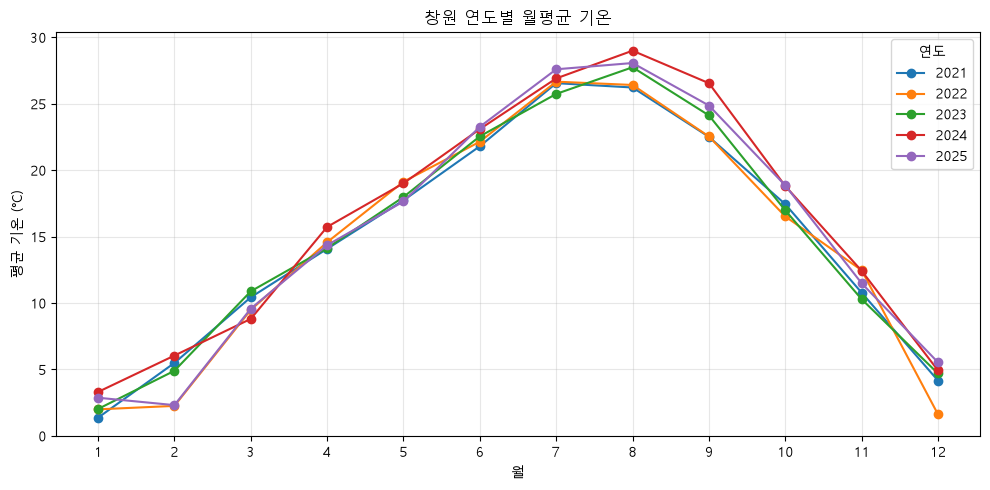

In [3]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

mean_temp_col = next(col for col in weather.columns if col.startswith('평균기온'))
weather[mean_temp_col] = pd.to_numeric(weather[mean_temp_col], errors='coerce')
weather['연도'] = weather[date_col].dt.year
weather['월'] = weather[date_col].dt.month
monthly_temp = weather.pivot_table(
    index='월', columns='연도', values=mean_temp_col, aggfunc='mean'
)

ax = monthly_temp.plot(marker='o', figsize=(10, 5))
ax.set(title='창원 연도별 월평균 기온', xlabel='월', ylabel='평균 기온 (°C)', xticks=range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title='연도')
plt.tight_layout()
plt.show()

## 시계열의 트렌드·계절성·노이즈

기온 시계열은 다음처럼 세 요소로 나누어 생각할 수 있습니다.

$$Y_t = T_t + S_t + R_t$$

여기서 $Y_t$는 관측 기온, $T_t$는 트렌드, $S_t$는 계절성, $R_t$는 잔차(노이즈)를 뜻합니다.

- **트렌드(Trend)**는 긴 기간에 걸쳐 기온이 전반적으로 상승하거나 하강하는 방향입니다. 일별 변화에 가려질 수 있으므로 같은 달의 연도별 평균이나 연평균을 비교해 살펴봅니다. 이 자료는 2021~2025년의 5년치이므로 기간 내 변화는 볼 수 있지만, 장기적인 기후변화로 단정하기에는 짧습니다.
- **계절성(Seasonality)**은 일정한 주기로 반복되는 패턴입니다. 창원 기온에서는 겨울에 낮고 여름에 높은 연간 주기를 기대할 수 있으며, 월별 선그래프의 반복 모양이나 연도·월 히트맵의 색 변화로 확인합니다. 해마다 정도가 달라도 반복되는 시점이 비슷하면 계절성으로 볼 수 있습니다.
- **노이즈(Noise)**는 트렌드와 계절성으로 설명되지 않는 불규칙한 흔들림입니다. 한파·폭염·비구름 같은 실제 날씨 변화와 관측 오차가 함께 포함될 수 있어, 노이즈라고 해서 잘못된 값이라는 뜻은 아닙니다. 상자그림의 이상치도 먼저 실제 기상 현상일 가능성을 고려합니다.

**그래프 읽기:** 연도별 월평균 선그래프에서 매년 되풀이되는 오르내림은 계절성, 여러 해에 걸친 전체적인 방향은 트렌드, 그 두 패턴에서 벗어난 변동은 노이즈의 후보입니다. 이 구분은 해석을 돕는 틀이며, 요소를 정확히 분리하려면 별도의 시계열 분해와 더 긴 관측 기간이 필요합니다.

## 이동평균과 변화율: 왜, 어떻게 적용할까?

### 1. 이동평균으로 큰 흐름 보기

월평균기온에는 계절에 따른 오르내림과 짧은 날씨 변동이 함께 들어 있습니다. **12개월 이동평균**은 연속된 12개월의 평균을 계산해 매년 반복되는 계절 변동을 완화하고, 그보다 느린 추세를 보기 쉽게 합니다. 원래 관측값을 덮어쓰는 처리가 아니라, 비교를 위한 평활선입니다.

이 노트북에서는 `center=True`로 앞뒤 12개월을 중심에 맞춰 계산합니다. 양쪽 기간을 모두 사용하는 방식이라 실시간 예측용이 아니며, 완전한 12개월 창이 없는 시작과 끝부분은 값이 비어 있습니다.

### 2. 전년 같은 달과 비교하기

계절성이 강한 날씨 자료는 바로 앞 달과 비교하면 계절 변화까지 섞입니다. 따라서 1월은 이전 해 1월과 비교하는 **전년 동월 차이**를 계산합니다.

$$\Delta T_t = T_t - T_{t-12}$$

기온은 섭씨($^\circ$C) 차이로 나타냅니다. 섭씨의 0도는 비율 계산의 기준점이 아니므로 기온의 퍼센트 변화율은 해석하기 어렵습니다. 강수량은 전년 동월 강수량이 0보다 클 때만 아래 퍼센트 변화를 계산합니다.

$$\%\Delta P_t = \frac{P_t - P_{t-12}}{P_{t-12}} \times 100$$

전년 강수량이 0이거나 결측이면 퍼센트 변화는 정의되지 않으므로 결측으로 둡니다. 기준 강수량이 아주 적으면 퍼센트가 크게 보일 수 있으니 변화율과 함께 실제 강수량(mm)도 확인해야 합니다.

### 3. 이 자료에서 해석할 때

첫 12개월은 전년 동월 비교값이 없어 비어 있습니다. 이동평균의 가장자리도 완전한 12개월 창이 없어서 비어 있습니다. 이 값들은 임의로 채우지 않습니다. 2021~2025년은 5년뿐이므로 이 분석은 기간 내 패턴을 요약하는 용도이며, 장기 기후 추세나 예측으로 확대 해석하지 않습니다.

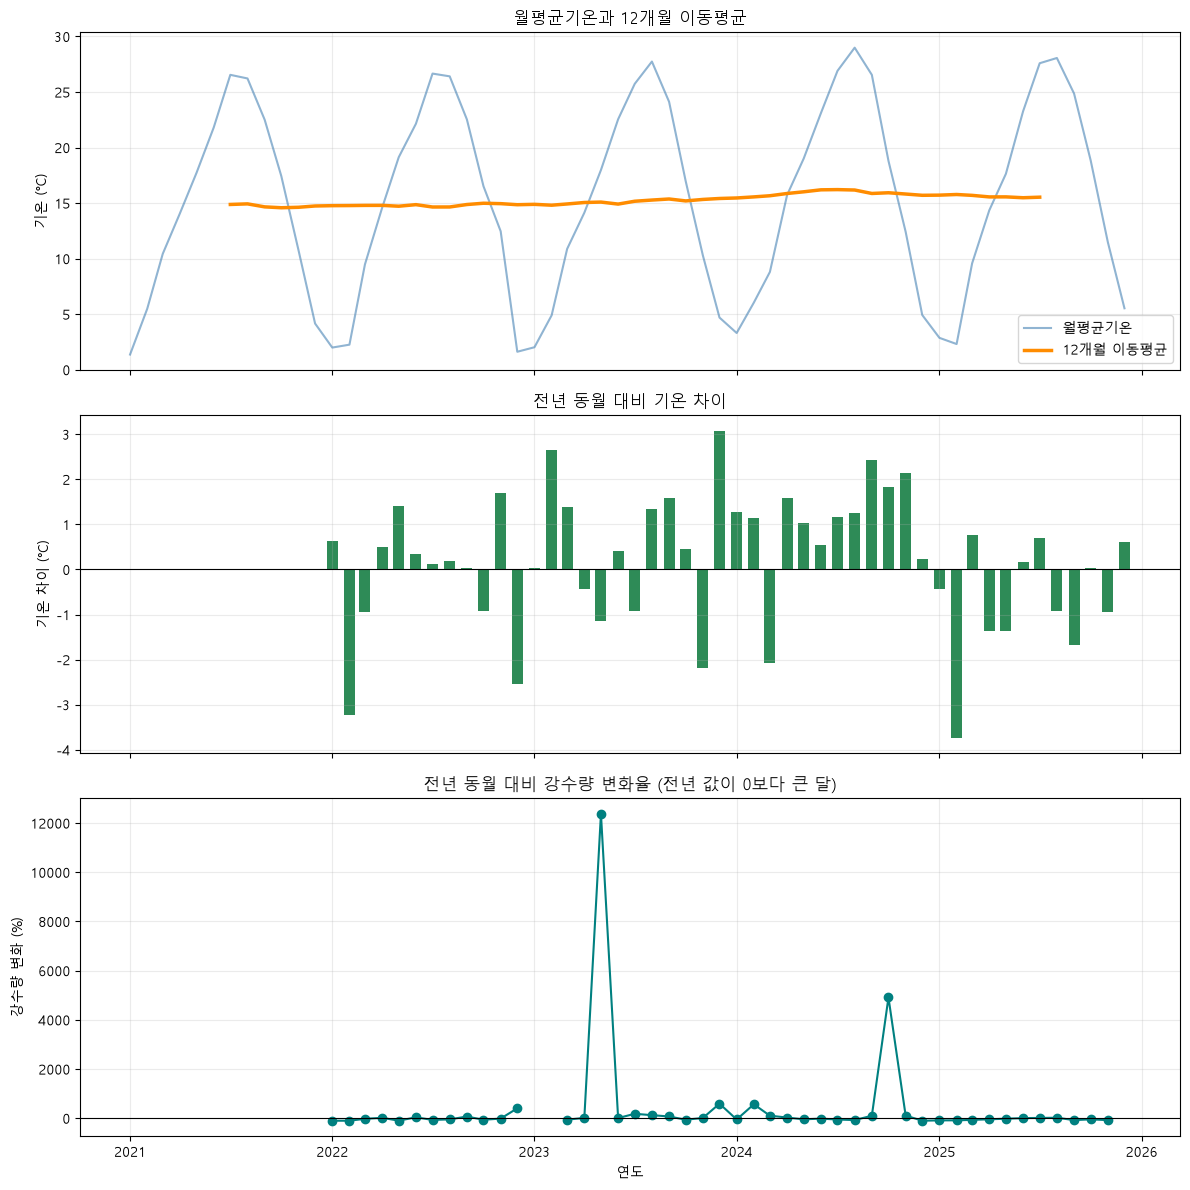

월별 기온 관측값: 60개월
12개월 이동평균 계산값: 49개월
전년 동월 기온 비교값: 48개월
정의 가능한 강수량 변화율: 45개월


In [ ]:





monthly_temperature_series = (
    weather.set_index(date_col)[mean_temp_col].resample('MS').mean()
)
temperature_ma_12 = monthly_temperature_series.rolling(
    window=12, center=True, min_periods=12
).mean()
temperature_yoy_difference = monthly_temperature_series.diff(periods=12)

rainfall_col = next(col for col in weather.columns if col.startswith('일강수량'))
daily_rainfall = pd.to_numeric(weather[rainfall_col], errors='coerce')
monthly_rainfall_series = pd.Series(
    daily_rainfall.to_numpy(), index=weather[date_col]
).resample('MS').sum(min_count=1)
previous_year_rainfall = monthly_rainfall_series.shift(periods=12)
rainfall_yoy_percent = (
    (monthly_rainfall_series - previous_year_rainfall)
    / previous_year_rainfall.where(previous_year_rainfall > 0)
    * 100
)

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
axes[0].plot(
    monthly_temperature_series.index,
    monthly_temperature_series,
    color='steelblue',
    alpha=0.6,
    label='월평균기온',
)
axes[0].plot(
    temperature_ma_12.index,
    temperature_ma_12,
    color='darkorange',
    linewidth=2.5,
    label='12개월 이동평균',
)
axes[0].set_ylabel('기온 (°C)')
axes[0].set_title('월평균기온과 12개월 이동평균')
axes[0].legend()

axes[1].bar(
    temperature_yoy_difference.index,
    temperature_yoy_difference,
    width=20,
    color='seagreen',
)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('기온 차이 (°C)')
axes[1].set_title('전년 동월 대비 기온 차이')

axes[2].plot(
    rainfall_yoy_percent.index,
    rainfall_yoy_percent,
    marker='o',
    color='teal',
)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_ylabel('강수량 변화 (%)')
axes[2].set_xlabel('연도')
axes[2].set_title('전년 동월 대비 강수량 변화율 (전년 값이 0보다 큰 달)')

for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f'월별 기온 관측값: {monthly_temperature_series.notna().sum()}개월')
print(f'12개월 이동평균 계산값: {temperature_ma_12.notna().sum()}개월')
print(f'전년 동월 기온 비교값: {temperature_yoy_difference.notna().sum()}개월')
print(f'정의 가능한 강수량 변화율: {rainfall_yoy_percent.notna().sum()}개월')

## 연도별 월강수량

일강수량을 월별로 합산합니다. 비어 있는 값은 합산에서 제외됩니다.

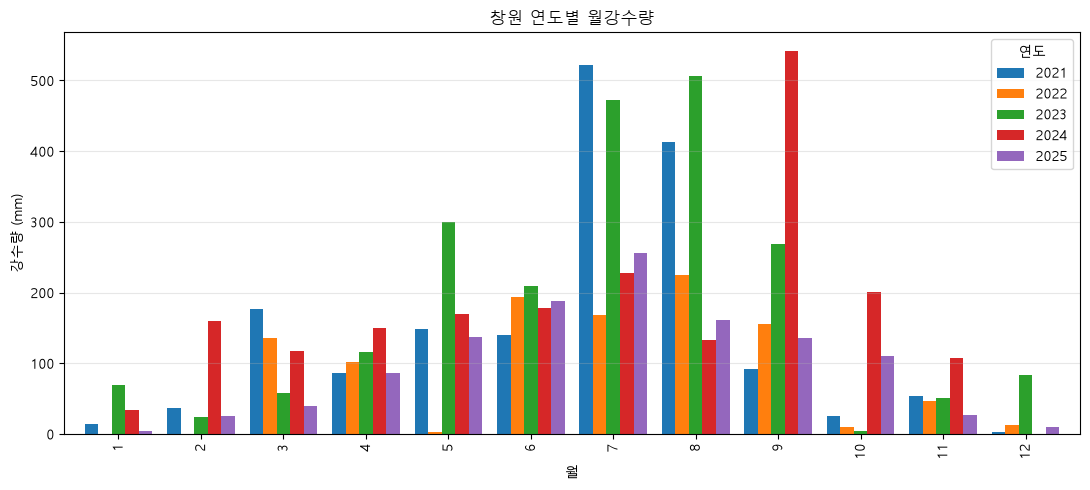

In [5]:
rain_col = next(col for col in weather.columns if col.startswith('일강수량'))
weather[rain_col] = pd.to_numeric(weather[rain_col], errors='coerce')
monthly_rain = weather.pivot_table(
    index='월', columns='연도', values=rain_col,
    aggfunc=lambda values: values.sum(min_count=1),
)

ax = monthly_rain.plot(kind='bar', figsize=(11, 5), width=0.82)
ax.set(title='창원 연도별 월강수량', xlabel='월', ylabel='강수량 (mm)')
ax.grid(axis='y', alpha=0.3)
ax.legend(title='연도')
plt.tight_layout()
plt.show()

## 추가 시각화

히트맵은 연도별 월평균 기온, 상자그림은 월별 일평균기온의 5년 분포, 산점도는 월평균 기온과 월강수량의 관계를 보여줍니다.

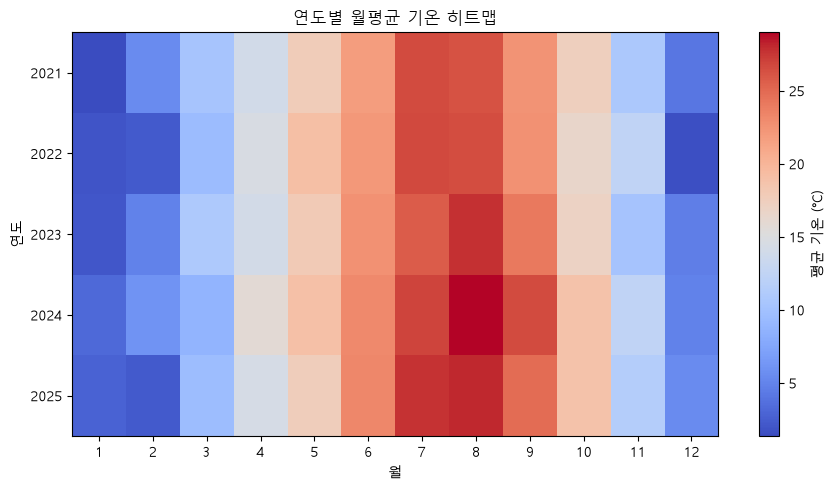

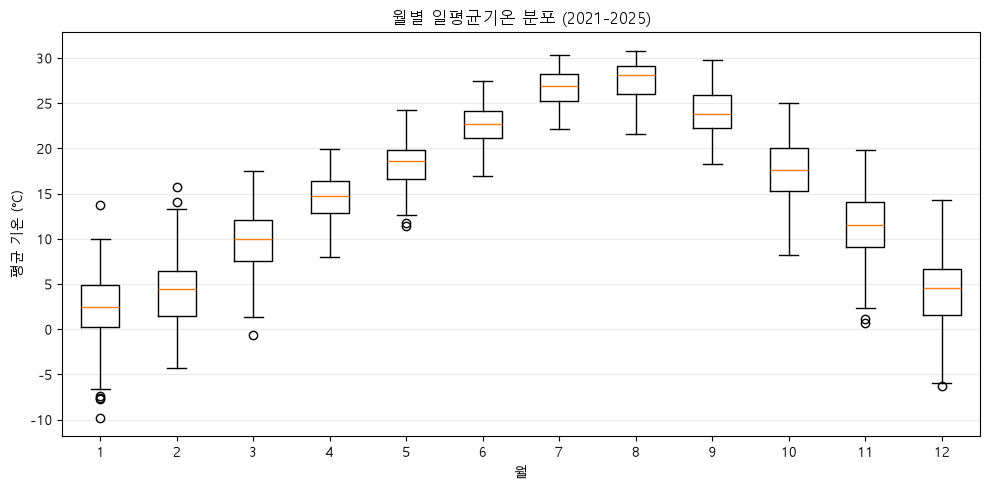

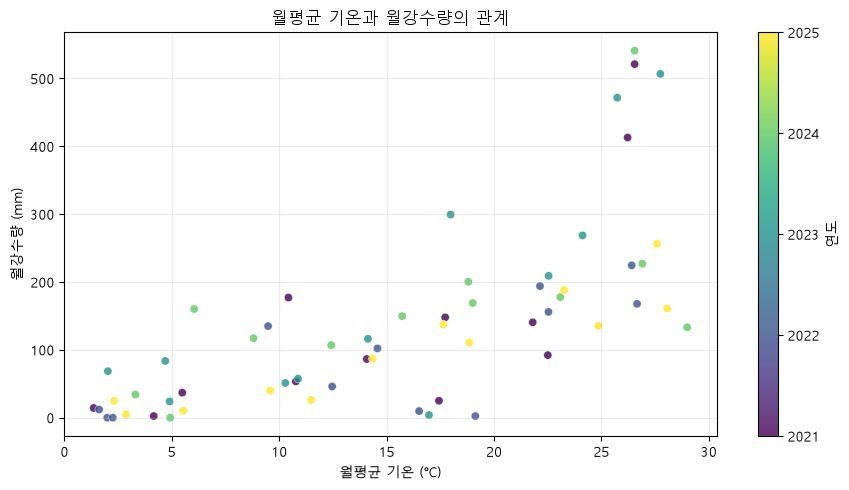

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
heatmap = ax.imshow(monthly_temp.T, aspect='auto', cmap='coolwarm')
ax.set(title='연도별 월평균 기온 히트맵', xlabel='월', ylabel='연도')
ax.set_xticks(range(12), labels=range(1, 13))
ax.set_yticks(range(len(monthly_temp.columns)), labels=monthly_temp.columns.astype(str))
fig.colorbar(heatmap, ax=ax, label='평균 기온 (°C)')
plt.tight_layout()
plt.show()

monthly_temp_distributions = [
    weather.loc[weather['월'] == month, mean_temp_col].dropna()
    for month in range(1, 13)
]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(monthly_temp_distributions, showfliers=True)
ax.set_xticks(range(1, 13), labels=range(1, 13))
ax.set(title='월별 일평균기온 분포 (2021-2025)', xlabel='월', ylabel='평균 기온 (°C)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

monthly_climate = weather.groupby(['연도', '월']).agg(
    월평균기온=(mean_temp_col, 'mean'),
    월강수량=(rain_col, lambda values: values.sum(min_count=1)),
).reset_index()
fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(
    monthly_climate['월평균기온'],
    monthly_climate['월강수량'],
    c=monthly_climate['연도'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='white',
    linewidths=0.4,
)
ax.set(title='월평균 기온과 월강수량의 관계', xlabel='월평균 기온 (°C)', ylabel='월강수량 (mm)')
ax.grid(alpha=0.25)
fig.colorbar(points, ax=ax, label='연도', ticks=monthly_climate['연도'].unique())
plt.tight_layout()
plt.show()

## 핵심 인사이트

1. **뚜렷한 연중 계절성:** 월평균기온은 1월 **2.31°C**로 가장 낮고 8월 **27.49°C**로 가장 높았습니다. 차이는 **25.17°C**이며, 선그래프와 히트맵에서 겨울 저온·여름 고온의 반복 패턴이 확인됩니다.
2. **연도별 평균 차이:** 일평균기온의 연평균은 2021년 **14.93°C**, 2022년 **14.71°C**, 2023년 **15.22°C**, 2024년 **16.23°C**, 2025년 **15.61°C**입니다. 가장 높은 2024년과 가장 낮은 2022년의 차이는 **1.52°C**로, 한 해의 값만으로 장기 추세를 단정하기 어렵습니다.
3. **전년 동월 변동:** 전년 동월 대비 기온 차이는 2023년 12월 **+3.08°C**로 가장 컸고, 2025년 2월 **−3.73°C**로 가장 작았습니다. 연중 계절 영향을 줄여도 특정 월의 연도 간 변동은 남습니다.
4. **평활 추세의 변화:** 12개월 이동평균은 유효 구간의 시작인 2021년 7월 **14.88°C**에서 끝인 2025년 7월 **15.53°C**로 **0.66°C** 높아졌습니다. 이는 이 5년 구간의 요약일 뿐 장기 기후변화의 증거로 해석하지 않습니다.